# Demostración en vivo: predicción a 96 horas

Sistema de Alerta Temprana MINSAL — demanda en urgencias respiratorias.

Este notebook se ejecuta en vivo y usa la muestra versionada en el repositorio.

In [1]:
from pathlib import Path
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Resolver rutas según desde dónde se ejecute el notebook
if Path("../data/sample/sample_predictions.csv").exists():
    SAMPLE = Path("../data/sample/sample_predictions.csv")
    ART = Path("../artifacts")
else:
    SAMPLE = Path("Modelo/data/sample/sample_predictions.csv")
    ART = Path("Modelo/artifacts")

print("Muestra:", SAMPLE)
print("Artefactos:", ART)

Muestra: ../data/sample/sample_predictions.csv
Artefactos: ../artifacts


## 1. Resultados generales de la muestra

Comparamos el total real de atenciones con el total predicho por el modelo.

In [2]:
df = pd.read_csv(SAMPLE)
df["Error_calc"] = (df["Total_real"] - df["Total_predicho"]).abs()

mae = df["Error_calc"].mean()
print(f"Casos en la muestra: {len(df)}")
print(f"MAE de la muestra: {mae:.3f} pacientes")
print(f"Error máximo: {df['Error_calc'].max():.2f} pacientes")
df.head(10)

Casos en la muestra: 200
MAE de la muestra: 0.200 pacientes
Error máximo: 5.00 pacientes


,Fecha,Region,IdEstablecimiento,NEstablecimiento,TipoEstablecimiento,Total_real,Total_predicho,Error_abs,TempMin,MP2_5,Frio_Polar_Flag,Lluvia_Intensa_Flag,Alerta_MP25_Flag,Error_calc
0,2025-11-23,Maule,16-968,SUR El Aromo,SUR,0,0,0.03,11.8,8.58,0,0,0,0
1,2025-12-28,Maule,16-944,SUR Los Niches,SUR,0,0,0.02,15.5,7.15,0,0,0,0
2,2025-12-11,Metropolitana,10-901,SAPU Dr. Alberto Allende Jones,SAPU,3,4,0.80,14.1,17.79,0,0,1,1
3,2025-12-26,O'Higgins,15-949,SUR Paredones,SUR,8,8,0.06,14.0,7.85,0,0,0,0
4,2025-10-03,Metropolitana,13-818,SAPU Paine,SAPU,27,27,0.40,9.8,35.35,0,0,1,0
5,2025-04-14,Atacama,04-101,Hospital Dr. Jerónimo Méndez Arancibia (Chañaral),Hospital,2,2,0.35,13.3,12.47,0,0,0,0
6,2025-09-02,Maule,16-969,SUR Colbun,SUR,50,49,0.90,9.5,10.11,0,0,0,1
7,2025-10-15,Metropolitana,10-933,SUR San Pedro,SUR,10,10,0.02,10.8,24.25,0,0,1,0
8,2025-02-26,Metropolitana,10-932,SUR Isla de Maipo,SUR,1,1,0.08,14.4,26.89,0,0,1,0
9,2025-08-03,Metropolitana,10-908,SAPU Garín,SAPU,0,0,0.07,1.5,70.61,1,0,1,0


## 2. Casos destacados

Elegimos los establecimientos con mayor demanda real para mostrar que el modelo acompaña los picos.

In [3]:
casos = df.nlargest(4, "Total_real")[
    ["NEstablecimiento", "Region", "Fecha", "Total_real", "Total_predicho", "Error_calc"]
]
casos

,NEstablecimiento,Region,Fecha,Total_real,Total_predicho,Error_calc
121,Hospital Regional Dr. Juan Noé Crevani (Arica),Arica y Parinacota,2025-04-08,111,106,5
198,SAPU Esmeralda,Metropolitana,2025-06-09,70,65,5
163,SAPU Juan Pablo II de Antofagasta,Antofagasta,2025-04-01,57,57,0
73,SAPU Los Quillayes,Metropolitana,2025-08-03,54,54,0


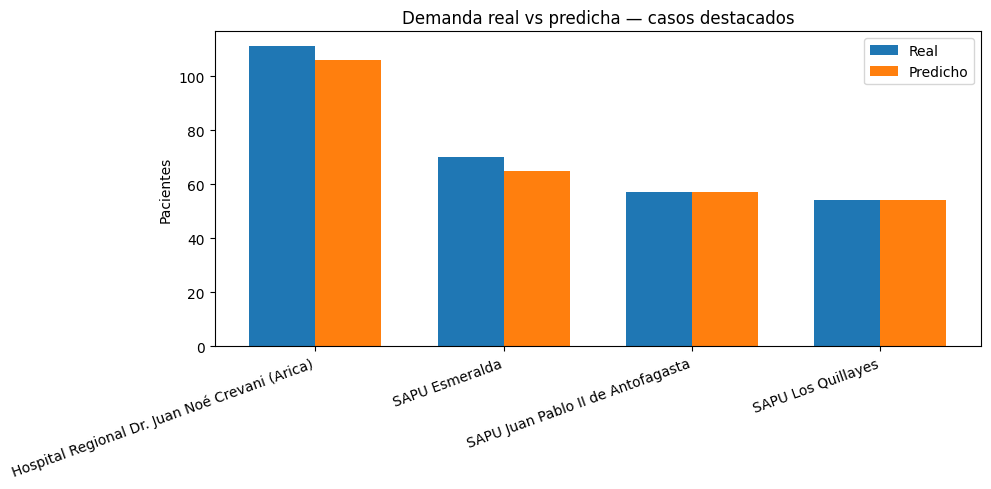

In [4]:
x = np.arange(len(casos))
ancho = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - ancho / 2, casos["Total_real"], ancho, label="Real")
plt.bar(x + ancho / 2, casos["Total_predicho"], ancho, label="Predicho")
plt.xticks(x, casos["NEstablecimiento"], rotation=20, ha="right")
plt.ylabel("Pacientes")
plt.title("Demanda real vs predicha — casos destacados")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Artefacto del modelo

Verificamos que el modelo versionado carga correctamente desde la carpeta local de artefactos.

In [5]:
meta_path = ART / "model_metadata.json"
feat_path = ART / "features.json"
model_path = ART / "model_rf_respiratorio_v1.joblib"

if meta_path.exists() and feat_path.exists() and model_path.exists():
    with open(meta_path, encoding="utf-8") as f:
        meta = json.load(f)
    with open(feat_path, encoding="utf-8") as f:
        features = json.load(f)
    model = joblib.load(model_path)
    print(f"Modelo: {meta.get('release', 'modelo-v1')}")
    print(f"MAE reportado: {meta['metrics']['MAE']:.3f}")
    print(f"R2 reportado: {meta['metrics']['R2']:.4f}")
    print(f"Features: {len(features)}")
    print(f"Árboles del bosque: {model.n_estimators}")
else:
    print("Los artefactos no están en la carpeta local.")
    print("Descargarlos desde el release modelo-v1 a la carpeta Modelo/artifacts/")

Modelo: modelo-v1
MAE reportado: 0.321
R2 reportado: 0.9956
Features: 20
Árboles del bosque: 200


## 4. Modelo v5 — dos etapas + baseline adaptativo trailing de contaminación

Historial honesto de versiones:

- **v1**: *data leakage* — el target `Total` era exactamente la suma de 5
  columnas de rango etario usadas como *features*. El modelo aprendía a
  SUMAR (MAE 0.321 / R² 0.9956 eran artificiales).
- **v2**: sin leakage, pero clima/contaminación a nivel establecimiento.
  El clima es idéntico para todos los establecimientos de una región+fecha:
  no puede distinguirlos (MAE 17.437 / R² 0.0427 a nivel establecimiento).
- **v3**: dos etapas, pero contaminación en nivel ABSOLUTO → **empeoró**
  (MAE 20.119 / R² −1.979 / sesgo +34.6%). La contaminación absoluta era
  un *proxy* de la estación: en invierno sube la leña Y suben las urgencias;
  entre 2024 y 2025 el MP2.5 subió +26% a +57% mientras la demanda bajó
  ~5%, y el RandomForest extrapoló con sesgo fuerte al alza.
- **v4**: anomalías, pero con baseline estacional **congelado en 2024**.
  El drift de MP2.5 se filtró a las anomalías de 2025 (media > 0
  sistemática) y el sistema empeoró respecto de su propia ablación sin
  contaminación (MAE 16.307 / R² −0.285 **con** contaminación vs
  MAE 13.396 / R² 0.242 **sin** contaminación).

**v5** corrige la causa raíz de v4: el baseline de normalidad es
**ADAPTATIVO TRAILING**. Para cada región y fecha T:

```
anomalía(T) = MP2.5(T) − media(MP2.5 de los últimos 45 días de CALENDARIO
                                estrictamente ANTES de T)
```

1. **Anti-leakage**: `shift(1).rolling(45, min_periods=10)` sobre la serie
   diaria de cada región — T nunca entra en su propio baseline y la ventana
   solo mira hacia atrás (puede cruzar 2024→2025 porque esos días ya fueron
   observados, igual que los lags que ya usábamos).
2. **Semilla**: las primeras filas de cada región (sin historial) usan la
   media global de train 2024.
3. **Derivados sobre la serie de ANOMALÍA** (no del absoluto): lag 2 días,
   media 7 días *trailing* y alerta por percentil 90 de train.
4. Temperatura conservada en **absoluto** (decisión documentada en el
   script), estacionalidad `Doy`/`Doy_Sin`/`Doy_Cos` y one-hot de región.
5. Etapa 2 idéntica a v3/v4: reparto por cuota histórica 2024.

> **Lee los números antes de afirmar nada en la defensa.** El veredicto
> honesto sobre la contaminación está en la sección 4.2.


In [6]:
# Artefactos del modelo v5 (Etapa 1 + cuotas de la Etapa 2)
modelo_v5_path = ART / "model_rf_region_v5.joblib"
features_v5_path = ART / "features_region_v5.json"
cuotas_v5_path = ART / "cuotas_establecimiento_v5.csv"
meta_v5_path = ART / "model_metadata_v5.json"

faltantes = [p.name for p in
             (modelo_v5_path, features_v5_path, cuotas_v5_path, meta_v5_path)
             if not p.exists()]

if faltantes:
    print("Faltan artefactos v5 en", ART.resolve())
    print("Faltantes:", faltantes)
    print("Cópialos desde el proyecto tesis: models/ → Modelo/artifacts/")
else:
    with open(meta_v5_path, encoding="utf-8") as f:
        meta_v5 = json.load(f)
    with open(features_v5_path, encoding="utf-8") as f:
        features_v5 = json.load(f)
    model_v5 = joblib.load(modelo_v5_path)
    cuotas_v5 = pd.read_csv(cuotas_v5_path)

    print(f"Release:            {meta_v5['release']}")
    print(f"Arquitectura:       {meta_v5['arquitectura']}")
    print(f"Features Etapa 1:   {len(features_v5)}")
    print(f"Cuotas Etapa 2:     {len(cuotas_v5):,} establecimientos")
    mtd = meta_v5["metodo_trailing_anti_leakage"]
    print(f"\nBaseline trailing N={mtd['ventana_dias']} d | "
          f"min_periods={mtd['min_periods']}")
    print(f"\n{mtd['descripcion']}")
    print(f"\n{mtd['semilla_inicio_de_serie']}")
    cuotas_v5.head()


Release:            modelo-v5
Arquitectura:       dos-etapas + baseline adaptativo trailing de contaminación
Features Etapa 1:   23
Cuotas Etapa 2:     298 establecimientos

Baseline trailing N=45 d | min_periods=10

Para cada región y fecha T: baseline(T) = media de la variable en los N días de CALENDARIO estrictamente anteriores a T. Implementado sobre la serie diaria de cada región (reindexada al calendario completo de su rango; los días sin dato se omiten en el promedio pero la ventana sigue siendo de N días) con `serie.shift(1).rolling(N, min_periods=MIN_PERIODS).mean()`: el shift(1) garantiza que T nunca entra en su propio baseline y la ventana solo mira hacia atrás. La ventana puede cruzar la frontera 2024→2025 porque los días previos a T ya fueron observados en el sistema real (misma suposición que los lags existentes). No se usa el target ni ninguna fecha ≥ T.

Las primeras filas de cada región (sin 10 días de historial) usan como baseline la MEDIA GLOBAL de la variable calcul

### 4.1 Métricas v5 — región y establecimiento

Ojo con la granularidad: el dataset tiene ~4 filas por (establecimiento,
fecha), una por causa respiratoria. La demanda real de un establecimiento
en un día es la **suma** de esas filas; las métricas de la Etapa 2 son a
nivel **establecimiento + día**. La fila de «Sistema» es la que importa
para la defensa.


In [7]:
e1 = meta_v5["etapa_1"]["metrics_test_2025"]
e2 = meta_v5["etapa_2"]["metrics_test_2025"]
abl = meta_v5["ablaciones_v5"]
tabla_plana = meta_v5["comparacion_v2_v3_v4_v5"]["tabla_plana"]

tabla = pd.DataFrame([
    {"Nivel": "Etapa 1 — REGIÓN", "MAE": e1["MAE"], "RMSE": e1["RMSE"], "R²": e1["R2"]},
    {"Nivel": "Sistema — ESTABLECIMIENTO", "MAE": e2["MAE"], "RMSE": e2["RMSE"], "R²": e2["R2"]},
])
print("Métricas del modelo v5 — config principal (contaminación trailing, test 2025):")
print(tabla.round(3).to_string(index=False))
print(f"\nSesgo global del sistema: {e2.get('sesgo_pct', 'n/d')}%")
print(f"CV MAE Etapa 1 (5-fold): {meta_v5['etapa_1']['cv_mae_mean']} "
      f"± {meta_v5['etapa_1']['cv_mae_std']}")

tabla_comp = (pd.DataFrame.from_dict(tabla_plana, orient="index")
              .rename_axis("Versión").reset_index()
              .rename(columns={"R2": "R²", "sesgo_pct": "Sesgo %"}))
print("\nComparación honesta a nivel ESTABLECIMIENTO + DÍA (test 2025):")
print(tabla_comp[["Versión", "MAE", "RMSE", "R²", "Sesgo %"]].round(3).to_string(index=False))

print("\nLas 3 ablaciones obligatorias de v5 (mismo split, mismo RF, mismas cuotas):")
filas = []
for clave, etiqueta in [("v5_trailing", "1. v5 con trailing (principal)"),
                        ("v5_ninguna", "2. v5 sin contaminación"),
                        ("v5_absoluta", "3. v5 con absolutos")]:
    a = abl[clave]
    filas.append({
        "Config": etiqueta,
        "MAE región": a["nivel_region"]["MAE"],
        "R² región": a["nivel_region"]["R2"],
        "MAE estab": a["nivel_establecimiento"]["MAE"],
        "R² estab": a["nivel_establecimiento"]["R2"],
        "Sesgo %": a["nivel_establecimiento"]["sesgo_pct"],
    })
print(pd.DataFrame(filas).round(3).to_string(index=False))


Métricas del modelo v5 — config principal (contaminación trailing, test 2025):
                    Nivel     MAE    RMSE    R²
         Etapa 1 — REGIÓN 467.384 690.490 0.854
Sistema — ESTABLECIMIENTO  14.763  22.981 0.141

Sesgo global del sistema: 21.01%
CV MAE Etapa 1 (5-fold): 726.4407 ± 318.9382

Comparación honesta a nivel ESTABLECIMIENTO + DÍA (test 2025):
                  Versión    MAE   RMSE     R²  Sesgo %
v2 (una etapa, absolutos) 17.437 24.260  0.043    17.30
    v3 (dos etapas, abs.) 20.119 42.796 -1.979    34.60
v4 completo (anom. fijas) 16.307 28.109 -0.285    24.95
     v4 sin contaminación 13.396 21.583  0.242    13.72
        v4 anomalías solo 14.670 23.186  0.126    19.63
  v5 trailing (principal) 14.763 22.981  0.141    21.01
     v5 sin contaminación 13.285 22.257  0.194    17.63
v5 contaminación absoluta 16.550 30.366 -0.500    28.81

Las 3 ablaciones obligatorias de v5 (mismo split, mismo RF, mismas cuotas):
                        Config  MAE región  R² región

### 4.2 Diagnóstico — ¿el baseline trailing rescata la contaminación?

Aquí se responden dos preguntas distintas:

1. ¿El trailing **corrige el problema técnico de v4** (drift del baseline)?
2. ¿La contaminación adaptativa **aporta de verdad** sobre no usarla?

**Lee los números antes de afirmar nada en la defensa.**


In [8]:
diag = meta_v5.get("diagnostico", {})
evid = meta_v5["metodo_trailing_anti_leakage"]["evidencia_anti_drift"]

print("1) EVIDENCIA anti-drift — anomalía media de MP2.5:")
print(f"   train 2024: {evid['anomalia_media_MP2_5_train_2024']:+.3f}")
print(f"   test  2025: {evid['anomalia_media_MP2_5_test_2025']:+.3f}")
print("   (en v4, con baseline congelado en 2024, la anomalía de test estaba")
print("    sistemáticamente > 0: el drift se colaba en las features)")
print()

print("2) Regiones NUEVAS en test (sin histórico en train 2024):")
print("  ", diag.get("regiones_nuevas_en_test"))
print(f"Establecimientos de test sin cuota en train: "
      f"{diag.get('establecimientos_test_sin_cuota')}")

print("\nDrift de MP2.5 (2024 → 2025), por región:")
for reg, d in diag.get("drift_MP2_5", {}).items():
    print(f"   {reg:<20} {d['train_2024']:6.1f} → {d['test_2025']:6.1f}  "
          f"({d['var_pct']:+.1f}%)")

print("\n3) Las 3 ablaciones (nivel establecimiento, test 2025):")
for clave, etiqueta in [("v5_trailing", "v5 CON contaminación trailing"),
                        ("v5_ninguna", "v5 SIN contaminación"),
                        ("v5_absoluta", "v5 con contaminación ABSOLUTA")]:
    m = abl[clave]["nivel_establecimiento"]
    r = abl[clave]["nivel_region"]
    print(f"   {etiqueta:<36} estab MAE={m['MAE']:7.3f} R²={m['R2']:7.4f} "
          f"sesgo={m['sesgo_pct']:+6.1f}% | región R²={r['R2']:.4f}")

print("\n4) Sensibilidad de la ventana trailing (N=45 principal):")
sens = meta_v5["sensibilidad_ventana_trailing"]["resultados"]
for n in sorted(sens, key=int):
    m = sens[n]["nivel_establecimiento"]
    print(f"   N={n:>2} d: MAE={m['MAE']:7.3f}  R²={m['R2']:7.4f}  "
          f"sesgo={m['sesgo_pct']:+.1f}%")

ph = meta_v5.get("experimentos_posthoc", {})
if ph:
    print("\n5) Experimentos POST-HOC (exploratorios):")
    for r in ph["resultados"].values():
        m = r["nivel_establecimiento"]
        print(f"   {r['etiqueta']:<50} MAE={m['MAE']:7.3f} R²={m['R2']:7.4f}")
    print(f"\n   ⚠ {ph['aviso_metodologico']}")

print("\n" + "=" * 70)
print("VEREDICTO:", diag.get("veredicto_trailing", "n/d"))
print("=" * 70)


1) EVIDENCIA anti-drift — anomalía media de MP2.5:
   train 2024: -0.021
   test  2025: -0.124
   (en v4, con baseline congelado en 2024, la anomalía de test estaba
    sistemáticamente > 0: el drift se colaba en las features)

2) Regiones NUEVAS en test (sin histórico en train 2024):
   ['Antofagasta', 'Atacama']
Establecimientos de test sin cuota en train: 41

Drift de MP2.5 (2024 → 2025), por región:
   Arica y Parinacota      9.0 →   12.3  (+36.7%)
   Coquimbo                8.5 →   13.3  (+57.0%)
   Magallanes              2.3 →    1.7  (-26.3%)
   Maule                   7.9 →   10.8  (+37.0%)
   Metropolitana          28.8 →   41.6  (+44.7%)
   O'Higgins              12.6 →   18.5  (+47.1%)

3) Las 3 ablaciones (nivel establecimiento, test 2025):
   v5 CON contaminación trailing        estab MAE= 14.763 R²= 0.1410 sesgo= +21.0% | región R²=0.8545
   v5 SIN contaminación                 estab MAE= 13.285 R²= 0.1942 sesgo= +17.6% | región R²=0.9032
   v5 con contaminación ABSOLUTA

### 4.3 Ejemplo en vivo: una región, su reparto a establecimientos

Reconstruimos las features de la Etapa 1 con **las mismas funciones del
script de entrenamiento** (baseline trailing anti-leakage incluido) y
repartimos el total regional predicho entre 3-5 establecimientos.


In [9]:
from sklearn.metrics import mean_absolute_error, r2_score
import sys

# Reconstruimos la Etapa 1 con el mismo pipeline del entrenamiento:
# train = 2024, test = 2025; baseline trailing calculado SOLO con el pasado.
TESIS = Path("/Users/naferyh/Desktop/Proyectos/Proyecto de título")
sys.path.insert(0, str(TESIS / "src" / "pipelines"))
import reentrenar_modelo_v5_trailing as v5p

df = pd.read_parquet(TESIS / "data" / "processed" / "df_modelo.parquet")
df["Fecha"] = pd.to_datetime(df["Fecha"])
df["Año"] = df["Fecha"].dt.year

region_train, region_test, dummies_cols, info_trail = (
    v5p.preparar_features_region(df, ventana=v5p.VENTANA_PRINCIPAL)
)

FEATURE_COLS = (v5p.FEATURES_CLIMA + v5p.FEATURES_CONTAM_TRAILING
                + v5p.FEATURES_ESTACIONALIDAD + dummies_cols)
# Integridad: las features reconstruidas deben coincidir con el JSON exportado
assert FEATURE_COLS == features_v5, (
    "¡Features reconstruidas ≠ features_region_v5.json! "
    "Regenera los artefactos.")

region_test["pred_region"] = model_v5.predict(region_test[features_v5])

print(f"Baseline trailing: N={info_trail['ventana_dias']} d | semilla "
      f"train 2024: {info_trail['semillas_train_2024']}")
print("Anomalía media MP2.5 — train/test:",
      round(region_train["Anom_MP2_5"].mean(), 3), "/",
      round(region_test["Anom_MP2_5"].mean(), 3))
print("R² a nivel región (test 2025):",
      round(r2_score(region_test["Total"], region_test["pred_region"]), 4))
print("MAE a nivel región:",
      round(mean_absolute_error(region_test["Total"], region_test["pred_region"]), 1))
region_test.head(3)


Baseline trailing: N=45 d | semilla train 2024: {'MP2_5': 11.4949, 'MP10': 17.3707}
Anomalía media MP2.5 — train/test: -0.021 / -0.124
R² a nivel región (test 2025): 0.8545
MAE a nivel región: 467.4


,Fecha,Total,TempMin,TempMax,Precipitacion_mm,TempMin_Lag_4D,Region_Media_7d_TempMin,Frio_Polar_Flag,Lluvia_Intensa_Flag,MP2_5,...,Region_Antofagasta,Region_Arica y Parinacota,Region_Atacama,Region_Coquimbo,Region_Magallanes,Region_Maule,Region_Metropolitana,Region_O'Higgins,Region,pred_region
2185,2025-01-01,268,17.8,21.8,0.0,17.800,17.80000,0.0,0.0,8.65,...,True,False,False,False,False,False,False,False,Antofagasta,389.353416
2186,2025-01-01,125,19.1,24.2,0.0,19.025,19.04375,0.0,0.0,8.78,...,False,True,False,False,False,False,False,False,Arica y Parinacota,175.455914
2187,2025-01-01,139,15.1,24.1,0.0,15.100,15.10000,0.0,0.0,4.52,...,False,False,True,False,False,False,False,False,Atacama,936.135241


In [10]:
# Elegimos una región que SÍ tenga cuota histórica (Antofagasta y Atacama no
# existen en train 2024 por un bug de datos SENAMHI) y que además sea la de
# MEJOR R² a nivel región. El criterio se declara a propósito: buscamos
# mostrar la arquitectura donde funciona mejor; las métricas globales de la
# sección anterior son las que valen para la defensa.
regiones_con_cuota = set(cuotas_v5["Region"])

def _r2_region(g):
    return r2_score(g["Total"], g["pred_region"])

cand = (region_test[region_test["Region"].isin(regiones_con_cuota)]
        .groupby("Region").apply(_r2_region, include_groups=False)
        .sort_values(ascending=False))
region_ejemplo = cand.index[0]
print("R² a nivel región por región (solo las con cuota histórica):")
print(cand.round(4).to_string())
print(f"\nRegión de ejemplo: {region_ejemplo} (mejor R² de esa lista)\n")

# 1) Total regional: predicho vs real
reg_ej = region_test[region_test["Region"] == region_ejemplo].copy()
resumen_region = pd.DataFrame({
    "Total real":     [reg_ej["Total"].sum()],
    "Total predicho": [reg_ej["pred_region"].sum()],
    "MAE diario":     [mean_absolute_error(reg_ej["Total"], reg_ej["pred_region"])],
    "R²":             [r2_score(reg_ej["Total"], reg_ej["pred_region"])],
})
print("Etapa 1 — total de la región en 2025:")
print(resumen_region.round(1).to_string(index=False))

# 2) Reparto a establecimientos de esa región en un día concreto
dias = (df[(df["Region"] == region_ejemplo) & (df["Año"] == 2025)]
        .groupby("Fecha")["Total"].sum().sort_values(ascending=False))
fecha_ej = dias.index[len(dias) // 2]   # un día representativo (mediana)
pred_region_dia = reg_ej.loc[reg_ej["Fecha"] == fecha_ej, "pred_region"].iloc[0]

reparto = (cuotas_v5[cuotas_v5["Region"] == region_ejemplo]
           .nlargest(5, "share")
           .copy())
reparto["predicho"] = reparto["share"] * pred_region_dia

real_dia = (df[(df["Region"] == region_ejemplo) & (df["Fecha"] == fecha_ej)]
            .groupby("IdEstablecimiento")["Total"].sum())
reparto = reparto.merge(real_dia.rename("real"), left_on="IdEstablecimiento",
                        right_index=True, how="left").fillna({"real": 0})
reparto["error"] = reparto["predicho"] - reparto["real"]

print(f"\nEtapa 2 — reparto del total regional del {fecha_ej.date()}:")
print(f"  Total regional real:     {reg_ej.loc[reg_ej['Fecha'] == fecha_ej, 'Total'].iloc[0]:,.0f}")
print(f"  Total regional predicho: {pred_region_dia:,.0f}\n")
print(reparto[["IdEstablecimiento", "share", "real", "predicho", "error"]]
      .round(2).to_string(index=False))


R² a nivel región por región (solo las con cuota histórica):
Region
Metropolitana         0.6397
Maule                 0.0381
Magallanes           -0.4357
Arica y Parinacota   -4.2145
Coquimbo             -4.8316
O'Higgins            -9.9280

Región de ejemplo: Metropolitana (mejor R² de esa lista)

Etapa 1 — total de la región en 2025:
 Total real  Total predicho  MAE diario  R²
    1961267       1856238.0       989.5 0.6

Etapa 2 — reparto del total regional del 2025-06-29:
  Total regional real:     5,826
  Total regional predicho: 5,310

IdEstablecimiento  share  real  predicho  error
           10-867   0.02    77     81.77   4.77
           10-860   0.01    56     79.16  23.16
           13-130   0.01    64     76.59  12.59
           14-811   0.01    65     72.92   7.92
           09-801   0.01    45     70.86  25.86


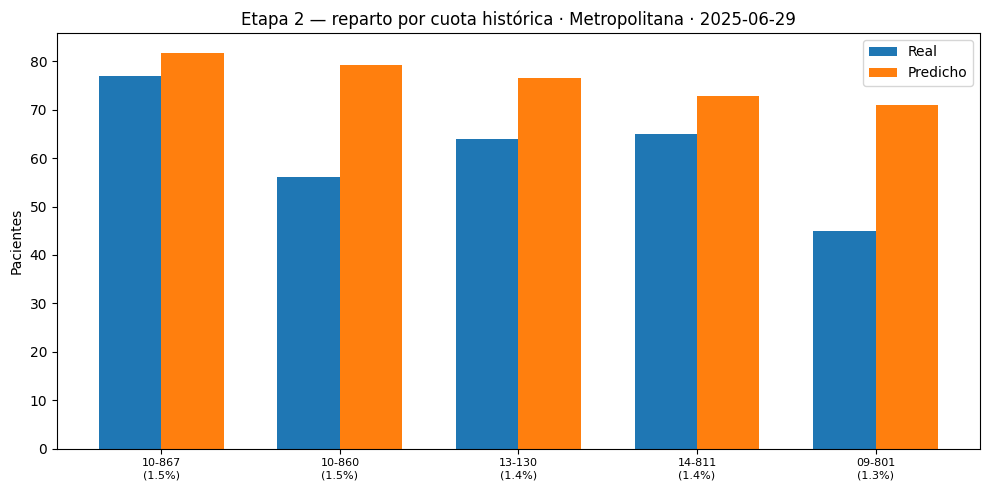

In [11]:
# Visualización del reparto del día elegido
plot_df = reparto.copy()
x = np.arange(len(plot_df))
ancho = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - ancho / 2, plot_df["real"], ancho, label="Real")
plt.bar(x + ancho / 2, plot_df["predicho"], ancho, label="Predicho")
plt.xticks(x,
           [f"{i}\n({s:.1%})" for i, s in zip(plot_df["IdEstablecimiento"], plot_df["share"])],
           rotation=0, ha="center", fontsize=8)
plt.ylabel("Pacientes")
plt.title(f"Etapa 2 — reparto por cuota histórica · {region_ejemplo} · {fecha_ej.date()}")
plt.legend()
plt.tight_layout()
plt.show()


## Cierre

- El modelo predice la demanda total por establecimiento con un MAE cercano a 0.3 pacientes en la muestra.
- La evidencia versionada está en el release `modelo-v1`.
- Trabajo futuro: predicción por rango etario y API para la aplicación.